# Периодический шум для генерации материалов

Сравниваем три карты при одинаковых seed и числе ячеек. Средний перепад через границу сопоставляем со средним перепадом соседних пикселей внутри карты. Ниже приведён снимок ядра `src/texgen/noise/core.py` для автономного запуска на Kaggle.

In [1]:
"""Периодический шум на единичном квадрате."""

import numpy as np
from numba import njit, prange


def sample(kind, x, y, cells=8, seed=42):
    """Вычисляет значения поля в заданных нормированных координатах. Параметр seed задаёт рисунок."""
    if not isinstance(cells, int) or not 2 <= cells <= 128:
        raise ValueError("cells must be an integer between 2 and 128")
    if not isinstance(seed, int) or seed < 0:
        raise ValueError("seed must be a nonnegative integer")
    rng = np.random.default_rng(seed)
    x, y = np.asarray(x) * cells, np.asarray(y) * cells
    ix, iy = np.floor(x).astype(int), np.floor(y).astype(int)
    u, v = x - ix, y - iy

    if kind == "perlin":
        angles = rng.uniform(0, 2 * np.pi, (cells, cells))
        def dot(dx, dy):
            angle = angles[(iy + dy) % cells, (ix + dx) % cells]
            return np.cos(angle) * (u - dx) + np.sin(angle) * (v - dy)

        def fade(t):
            return t**3 * (t * (6 * t - 15) + 10)

        a, b = fade(u), fade(v)
        value = (1-b) * ((1-a)*dot(0, 0) + a*dot(1, 0))
        value += b * ((1-a)*dot(0, 1) + a*dot(1, 1))
        return np.clip(0.5 + 0.5 * value, 0, 1)

    if kind == "voronoi":
        sites = rng.random((cells, cells, 2))
        best = np.full(np.broadcast_shapes(x.shape, y.shape), np.inf)
        # Расстояние до опорной точки в текущей ячейке не превышает её диагонали √2.
        for dy in range(-2, 3):
            for dx in range(-2, 3):
                offset = sites[(iy + dy) % cells, (ix + dx) % cells]
                dist2 = (u - dx - offset[..., 0])**2 + (v - dy - offset[..., 1])**2
                np.minimum(best, dist2, out=best)
        return np.sqrt(best / 2)
    raise ValueError("kind must be perlin or voronoi")


@njit
def _perlin(x, y, gx, gy, period):
    ix, iy = int(np.floor(x)), int(np.floor(y))
    u, v = x - ix, y - iy
    a = u**3 * (u * (6*u - 15) + 10)
    b = v**3 * (v * (6*v - 15) + 10)
    value = 0.0
    for dy in range(2):
        for dx in range(2):
            row, col = (iy + dy) % period, (ix + dx) % period
            dot = gx[row, col]*(u-dx) + gy[row, col]*(v-dy)
            value += dot * (a if dx else 1-a) * (b if dy else 1-b)
    return value


@njit
def _worley(x, y, sites):
    cells = sites.shape[0]
    ix, iy = int(np.floor(x)), int(np.floor(y))
    first, second = np.inf, np.inf
    for dy in range(-2, 3):
        for dx in range(-2, 3):
            site = sites[(iy + dy) % cells, (ix + dx) % cells]
            d = (x-ix-dx-site[0])**2 + (y-iy-dy-site[1])**2
            if d < first:
                second, first = first, d
            elif d < second:
                second = d
    return np.sqrt(first), np.sqrt(second)


@njit(parallel=True)
def _render(mode, axis, cells, gx, gy, sites):
    field = np.empty((axis.size, axis.size))
    for row in prange(axis.size):
        for col in range(axis.size):
            x, y = axis[col]*cells, axis[row]*cells
            if mode == 0:
                field[row,col] = 0.5 + 0.5*_perlin(x,y,gx,gy,cells)
            else:
                f1, f2 = _worley(x,y,sites)
                if mode == 1:
                    field[row,col] = f1 / np.sqrt(2.0)
                else:
                    # Смесь из опыта с бесшовным замощением в курсовой (ячейка с индексом 35).
                    total, weight, norm = 0.0, 1.0, 0.0
                    for octave in range(5):
                        scale = 2**octave
                        total += weight*_perlin(x*scale,y*scale,gx,gy,cells*scale)
                        norm += weight
                        weight *= 0.55
                    field[row,col] = 0.65*total/norm + 0.35*(f2-f1)
    return field


def generate(kind, size=512, cells=8, seed=42):
    if not isinstance(size, int) or not 2 <= size <= 4096:
        raise ValueError("size must be an integer between 2 and 4096")
    if not isinstance(cells, int) or not 2 <= cells <= 128:
        raise ValueError("cells must be an integer between 2 and 128")
    if not isinstance(seed, int) or seed < 0:
        raise ValueError("seed must be a nonnegative integer")
    modes = {"perlin": 0, "voronoi": 1, "combined": 2}
    if kind not in modes:
        raise ValueError(f"kind must be one of {tuple(modes)}")
    # Для каждой таблицы генератор стартует с того же seed, что и в базовой версии NumPy.
    width = cells*16 if kind == "combined" else cells
    angles = np.random.default_rng(seed).uniform(0, 2*np.pi, (width,width))
    sites = np.random.default_rng(seed).random((cells,cells,2))
    field = _render(modes[kind], np.arange(size)/size, cells,
                    np.cos(angles), np.sin(angles), sites)
    if kind == "combined":
        # Фиксированные коэффициенты сохраняют высоту в одной и той же точке при смене разрешения.
        field = 0.5 + 0.5*field
    return np.clip(field, 0, 1)

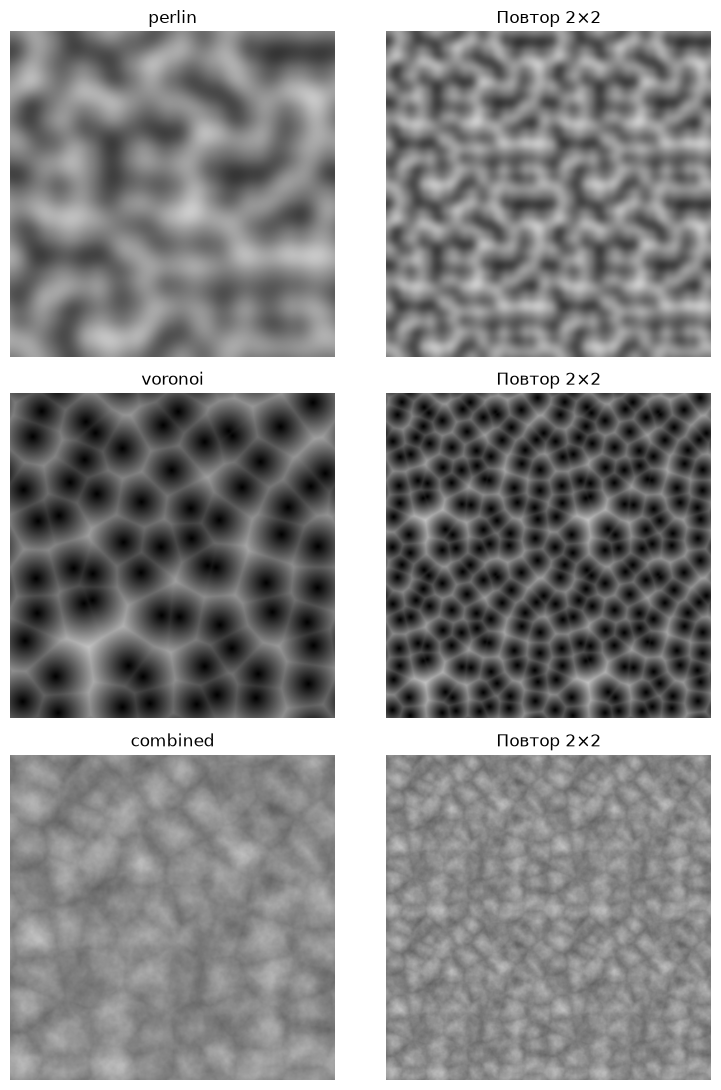

,Шум,Ось,Через стык,Внутри,Отношение
0,perlin,Y,0.005012,0.004548,1.102138
1,perlin,X,0.004099,0.003944,1.039112
2,voronoi,Y,0.008488,0.006927,1.225311
3,voronoi,X,0.009064,0.007001,1.294754
4,combined,Y,0.005827,0.004122,1.413656
5,combined,X,0.004815,0.004051,1.188690


In [2]:
import matplotlib.pyplot as plt
import pandas as pd

fig, axes = plt.subplots(3, 2, figsize=(8, 11))
rows = []
for (left, right), kind in zip(axes, ("perlin", "voronoi", "combined")):
    field = generate(kind, size=512, cells=8, seed=42)
    for ax, data, title in ((left, field, kind), (right, np.tile(field, (2, 2)), "Повтор 2×2")):
        ax.imshow(data, cmap="gray", vmin=0, vmax=1)
        ax.set_title(title)
        ax.axis("off")
    for axis, direction in enumerate(("Y", "X")):
        edge = np.abs(field.take(0, axis=axis) - field.take(-1, axis=axis)).mean()
        inside = np.abs(np.diff(field, axis=axis)).mean()
        rows.append([kind, direction, edge, inside, edge / inside if inside else np.nan])

fig.tight_layout()
plt.show()
display(pd.DataFrame(rows, columns=["Шум", "Ось", "Через стык", "Внутри", "Отношение"]))